# Check data

In [1]:
import pandas as pd
df = pd.read_csv('../data/adsorption/adsorption_gcmc_dataset.csv')
df.head()

,mol_uc_avg,n,temperature,adsorption_type,pressure
0,-17.854477,10,300,excess,1080000.0
1,0.003240,10,300,absolute,1080000.0
2,-17.797652,8,300,excess,1080000.0
3,1.168620,6,300,absolute,1080000.0
4,3.157465,4,300,excess,1080000.0


In [2]:
df.groupby('n').size().reset_index(name='count')

,n,count
0,2,242
1,4,242
2,6,242
3,8,242
4,10,242


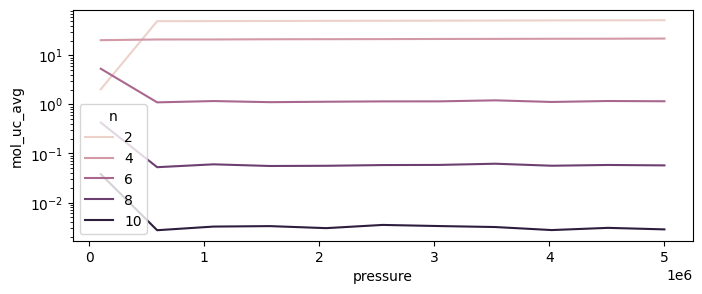

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(8, 3), dpi=100)

sns.lineplot(
    data=df.query('temperature == 300 and adsorption_type=="absolute"'),
    x='pressure',
    y='mol_uc_avg', hue='n')
ax.set_yscale('log')

# Make ml model

In [4]:
import pandas as pd
import numpy as np

data = pd.read_csv('../data/adsorption/adsorption_gcmc_dataset.csv')
data.head()

data['log_mol_uc_avg'] = data['mol_uc_avg'].apply(lambda x: -np.log10(np.abs(x)) if x < 0 else np.log10(x))
data['pressure_bar'] = data['pressure'] / 1e5
data['adsorption_type_num'] = data['adsorption_type'].map({'absolute': 0, 'excess': 1})

## Gaussian Process Regression for Adsorption Data

In [4]:
import joblib
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C, WhiteKernel

class AdsorptionGP(BaseEstimator):
    """
    A grouped Gaussian Process regressor for adsorption data that scales inputs and
    maintains one GP per combination of `n` and `adsorption_type_num`.
    Uses a Matérn ν=0.5 kernel (exponential kernel) with ARD, plus signal and noise kernels.
    """
    def __init__(self,
                 kernel=None,
                 alpha=0.0,
                 normalize_y=True,
                 length_scale=[1.0, 1.0],
                 length_scale_bounds=(1e-8, 1e5),
                 signal_level=1.0,
                 signal_bounds=(1e-3, 1e3),
                 noise_level=1e-5,
                 noise_bounds=(1e-8, 1e1),
                 n_restarts_optimizer=5):
        # ARD Matern kernel + signal scaling + white noise
        if kernel is None:
            matern = Matern(length_scale=length_scale,
                            length_scale_bounds=[length_scale_bounds]*2,
                            nu=0.5)
            signal = C(signal_level, signal_bounds)
            noise = WhiteKernel(noise_level=noise_level,
                                noise_level_bounds=noise_bounds)
            self.kernel = signal * matern + noise
        else:
            self.kernel = kernel
        self.alpha = alpha
        self.normalize_y = normalize_y
        self.n_restarts_optimizer = n_restarts_optimizer
        self.scaler = StandardScaler()
        # store one GP model per (n, adsorption_type_num)
        self.gp_models = {}

    def fit(self, data: pd.DataFrame, y_col: str = 'mol_uc_avg'):
        features = data[['pressure_bar', 'temperature']].values
        self.scaler.fit(features)

        groups = data.groupby(['n', 'adsorption_type_num'])
        for (n_val, ads_type), group in groups:
            X_grp = group[['pressure_bar', 'temperature']].values
            y_grp = group[y_col].values
            X_scaled = self.scaler.transform(X_grp)

            gp = GaussianProcessRegressor(
                kernel=self.kernel,
                alpha=self.alpha,
                normalize_y=self.normalize_y,
                n_restarts_optimizer=self.n_restarts_optimizer
            )
            gp.fit(X_scaled, y_grp)
            self.gp_models[(n_val, ads_type)] = gp
        return self

    def predict(self, df: pd.DataFrame) -> np.ndarray:
        preds = []
        for _, row in df.iterrows():
            key = (row['n'], row['adsorption_type_num'])
            gp = self.gp_models.get(key)
            if gp is None:
                preds.append(np.nan)
            else:
                pt = np.array([[row['pressure_bar'], row['temperature']]])
                pt_scaled = self.scaler.transform(pt)
                pred, std = gp.predict(pt_scaled, return_std=True)
                preds.append(pred[0])
        return np.array(preds)

    __call__ = predict


class AdsorptionGPSlopeExtrap(AdsorptionGP):
    """
    Same as AdsorptionGP for n<=10.
    For type 0 & n>10: extrapolate via log-slope from n=8 to n=10.
    For type 1 & n>10: hold flat at n=10.
    """
    def predict(self, df: pd.DataFrame) -> np.ndarray:
        base_preds = super().predict(df)
        df2 = df.reset_index(drop=True)
        preds = base_preds.copy()

        groups = df2.groupby(['pressure_bar', 'temperature', 'adsorption_type_num']).groups
        for (p, T, ads_t), idxs in groups.items():
            idxs = list(idxs)
            if ads_t == 0:
                mask8 = df2['n'] == 8
                mask10 = df2['n'] == 10
                y8 = [base_preds[i] for i in idxs if mask8.loc[i]]
                y10 = [base_preds[i] for i in idxs if mask10.loc[i]]
                if len(y8)==1 and len(y10)==1 and not np.isnan(y8[0]) and not np.isnan(y10[0]):
                    l8, l10 = np.log(y8[0]), np.log(y10[0])
                    slope = (l10 - l8) / 2.0
                    for i in idxs:
                        n_i = df2.at[i, 'n']
                        if n_i > 10:
                            preds[i] = np.exp(l10 + slope * (n_i - 10))
            else:
                mask10 = df2['n'] == 10
                y10 = [base_preds[i] for i in idxs if mask10.loc[i]]
                if len(y10)==1 and not np.isnan(y10[0]):
                    val10 = y10[0]
                    for i in idxs:
                        if df2.at[i, 'n'] > 10:
                            preds[i] = val10

        return preds

    __call__ = predict


ads_model = AdsorptionGPSlopeExtrap(
    kernel=None,
    alpha=0.0,
    normalize_y=True,
    length_scale=[0.5, 0.3],
    length_scale_bounds=(1e-14, 1e3),
    signal_level=0.7,
    signal_bounds=(1e-5, 1e3),
    noise_level=1e-5,
    noise_bounds=(1e-8, 1e1),
    n_restarts_optimizer=15
)
ads_model.fit(data, y_col='mol_uc_avg')
joblib.dump(ads_model, '../data/adsorption/adsorption_gp_model.pkl')

/home/aleksandr/miniconda3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/aleksandr/miniconda3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/aleksandr/miniconda3/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/aleksandr/miniconda3/lib/python3.12/site-packa

['../data/adsorption/adsorption_gp_model.pkl']

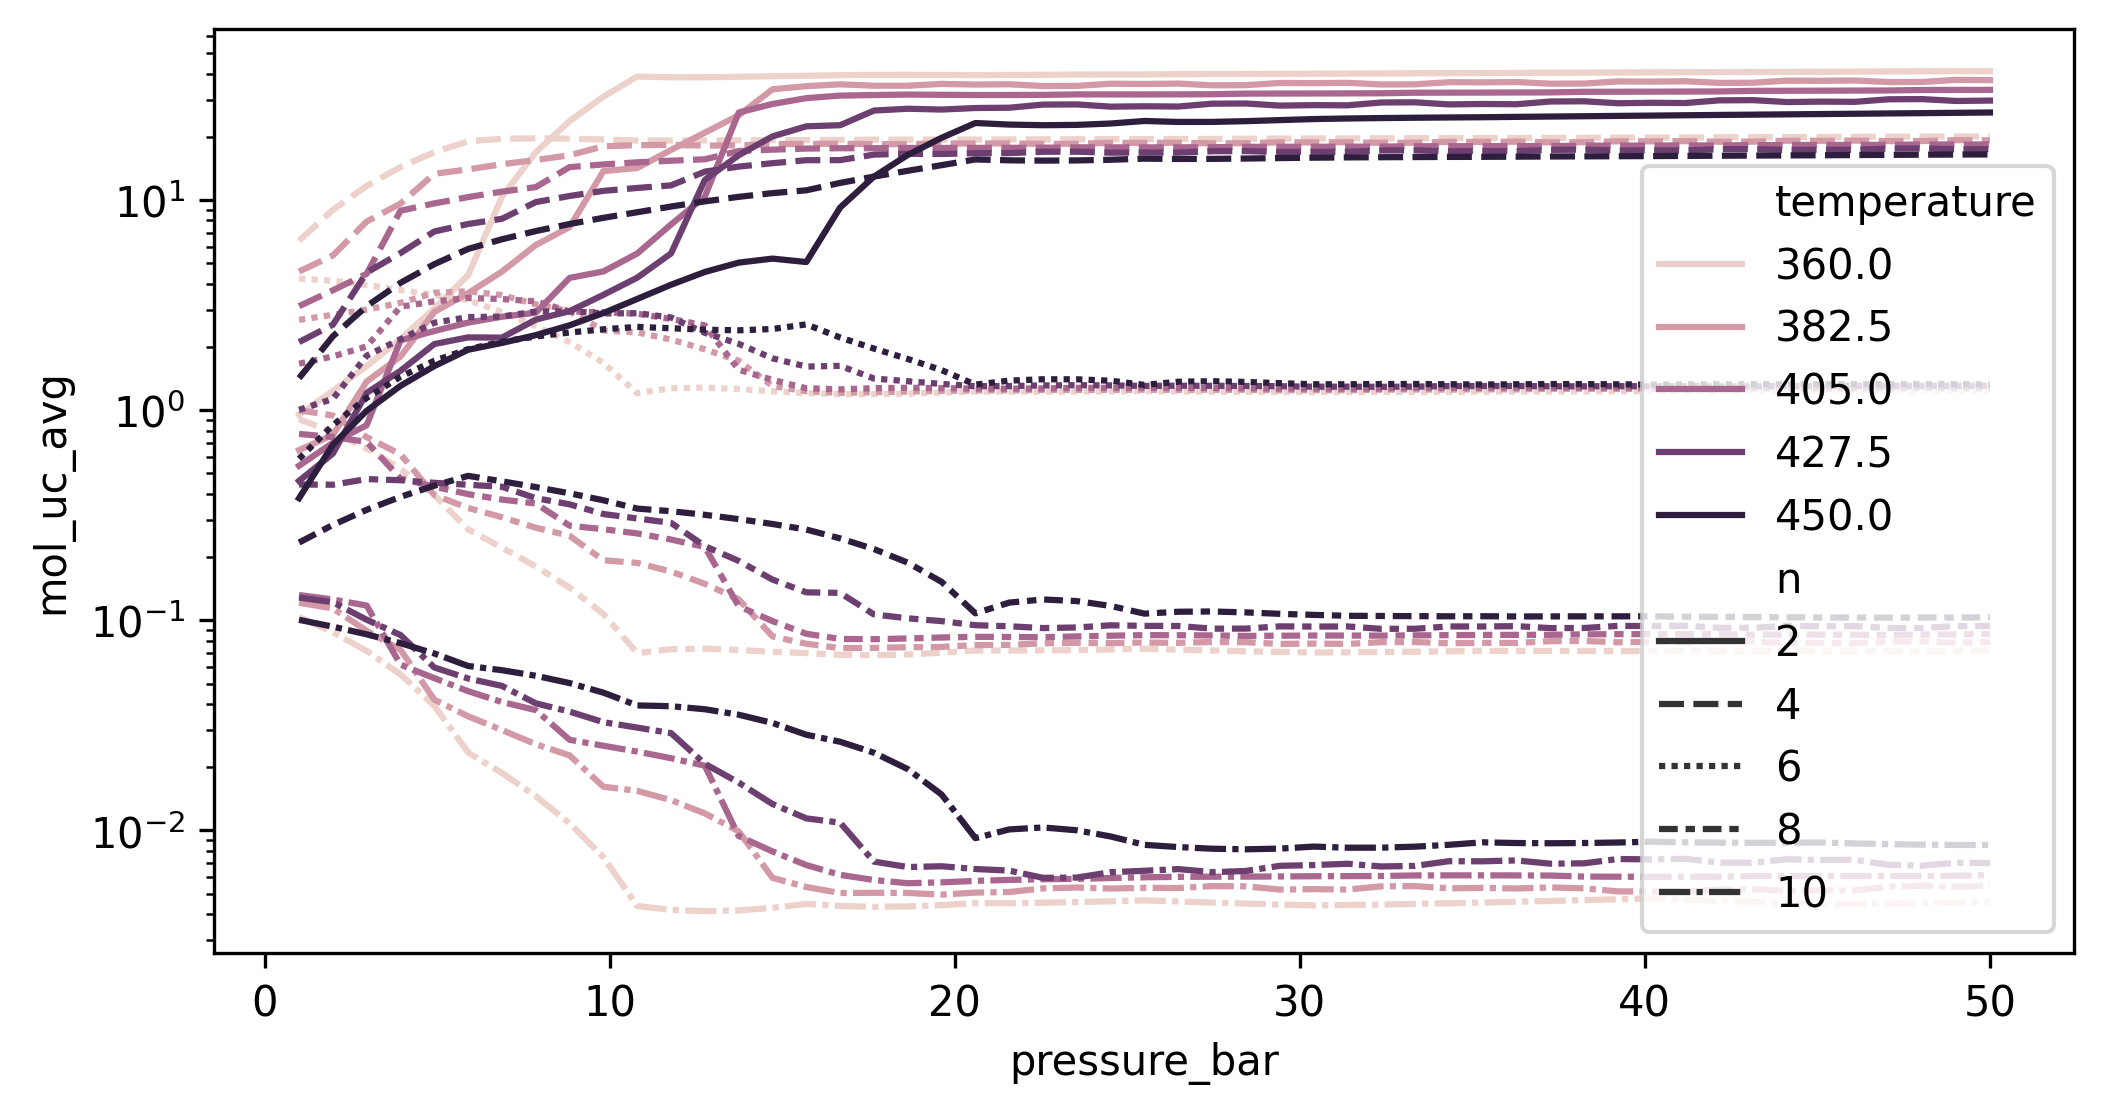

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axs = plt.subplots(1, 1, figsize=(8, 4), dpi=300)
ads_model_gp = joblib.load('../data/adsorption/adsorption_gp_model.pkl')
ads_model_knn = joblib.load('../data/processed/knn_adsorption_model_test.pkl')

class EnsembleModel:
    def __init__(self, model1, model2):
        self.model1 = model1
        self.model2 = model2

    def predict(self, X):
        y1 = self.model1(X)
        y2 = self.model2(X)
        return (y1 + y2) / 2

    __call__ = predict

ads_model_loaded = EnsembleModel(ads_model_gp, ads_model_knn)

joblib.dump(ads_model_loaded, '../data/adsorption/adsorption_ensemble_model.pkl')

m = 51
pressures = np.linspace(1, 50, m)
temperatures = np.linspace(360, 450, 5)
n = [2, 4, 6, 8, 10]
adsorption_types = [0]

# Create a DataFrame for predictions
X_test = pd.DataFrame([
    {'pressure_bar': p, 
     'temperature': temp, 
     'n': ni, 
     'adsorption_type_num': at}
    for p in pressures
    for temp in temperatures
    for ni in n
    for at in adsorption_types
])

y_pred = ads_model_loaded(X_test)
X_test['mol_uc_avg'] = y_pred
sns.lineplot(
    data=X_test,
    x='pressure_bar', y='mol_uc_avg',
    hue='temperature', style ='n', ax=axs
)
axs.set_yscale('log')

/tmp/ipykernel_8622/3158149329.py:24: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(


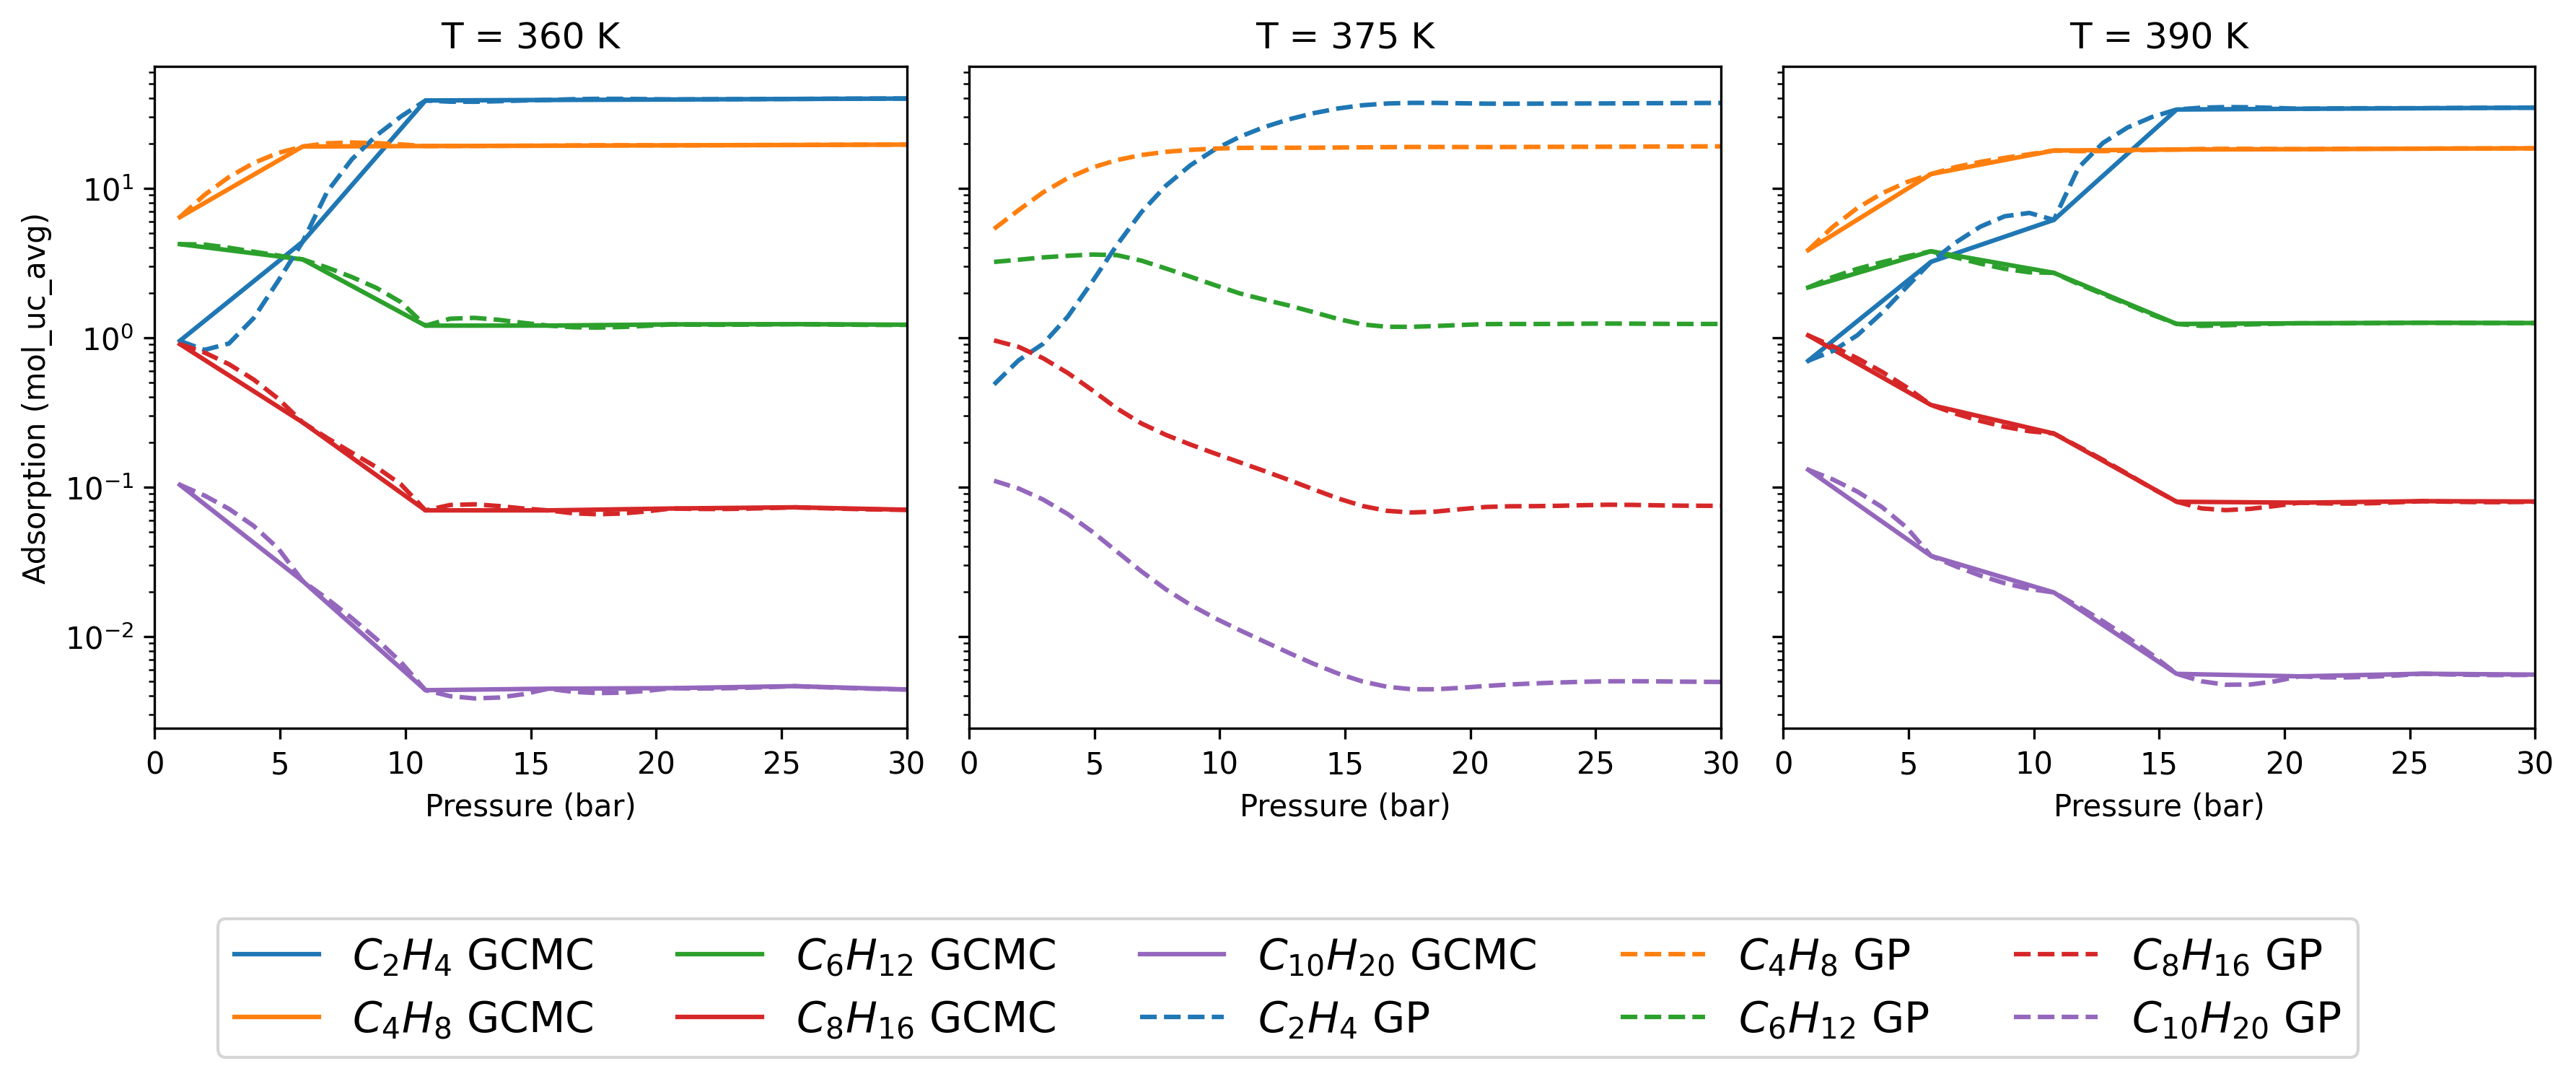

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# load your model and data
ads_model_loaded = joblib.load('../data/adsorption/adsorption_gp_model.pkl')

temps = [360, 375, 390]
# keep your same color‐mapping
palette = dict(zip(
    range(2, 11, 2),
    sns.color_palette('tab10', n_colors=5)
))

# set up a 2×3 figure
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=300, sharex=True, sharey=True)
axes = axes.flatten()

# common pressure axis
m = 51
pressure = np.linspace(1, 50, m)

for ax, T in zip(axes, temps):
    # plot the existing data
    sns.lineplot(
        data=data.query(
            'temperature == @T and adsorption_type=="absolute"'
        ),
        x='pressure_bar', y='mol_uc_avg',
        hue='n', palette=palette,
        ax=ax
    )

    # compute and plot predictions
    for n_val in range(2, 11, 2):
        X_test = pd.DataFrame({
            'pressure_bar': pressure,
            'temperature': [T] * m,
            'n':           [n_val] * m,
            'adsorption_type_num': [0] * m
        })
        y_pred = ads_model_loaded(X_test)
        ax.plot(
            pressure, y_pred,
            color=palette[n_val],
            linestyle='--',
            label=f'pred (n={n_val})'
        )

    ax.set_yscale('log')
    ax.set_title(f'T = {T} K')
    ax.set_xlabel('Pressure (bar)')
    ax.set_ylabel('Adsorption (mol_uc_avg)')
    ax.legend(fontsize='small', loc='upper left')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend_.remove()
    ax.set_xlim(0, 30)

labels = [f'$C_{{{n}}}H_{{{2*n}}}$ GCMC' for n in range(2, 11, 2)]
labels += [f'$C_{{{n}}}H_{{{2*n}}}$ GP' for n in range(2, 11, 2)]
fig.legend(
    handles=handles, labels=labels,
    title='',
    loc='upper center', bbox_to_anchor=(0.5, -0.05),
    ncol=5, fontsize=14
)
fig.tight_layout()
plt.show()

## Knn

In [5]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
import joblib
from kinetic_model.constants.adsorption import AdsorptionKNN

# Example usage:
# 1) Fit and save model
ads_model = AdsorptionKNN(n_neighbors=2)
ads_model.fit(data, y_col='mol_uc_avg')
joblib.dump(ads_model, '../data/processed/knn_adsorption_model_test.pkl')

['../data/processed/knn_adsorption_model_test.pkl']

/tmp/ipykernel_9221/2021800084.py:29: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(


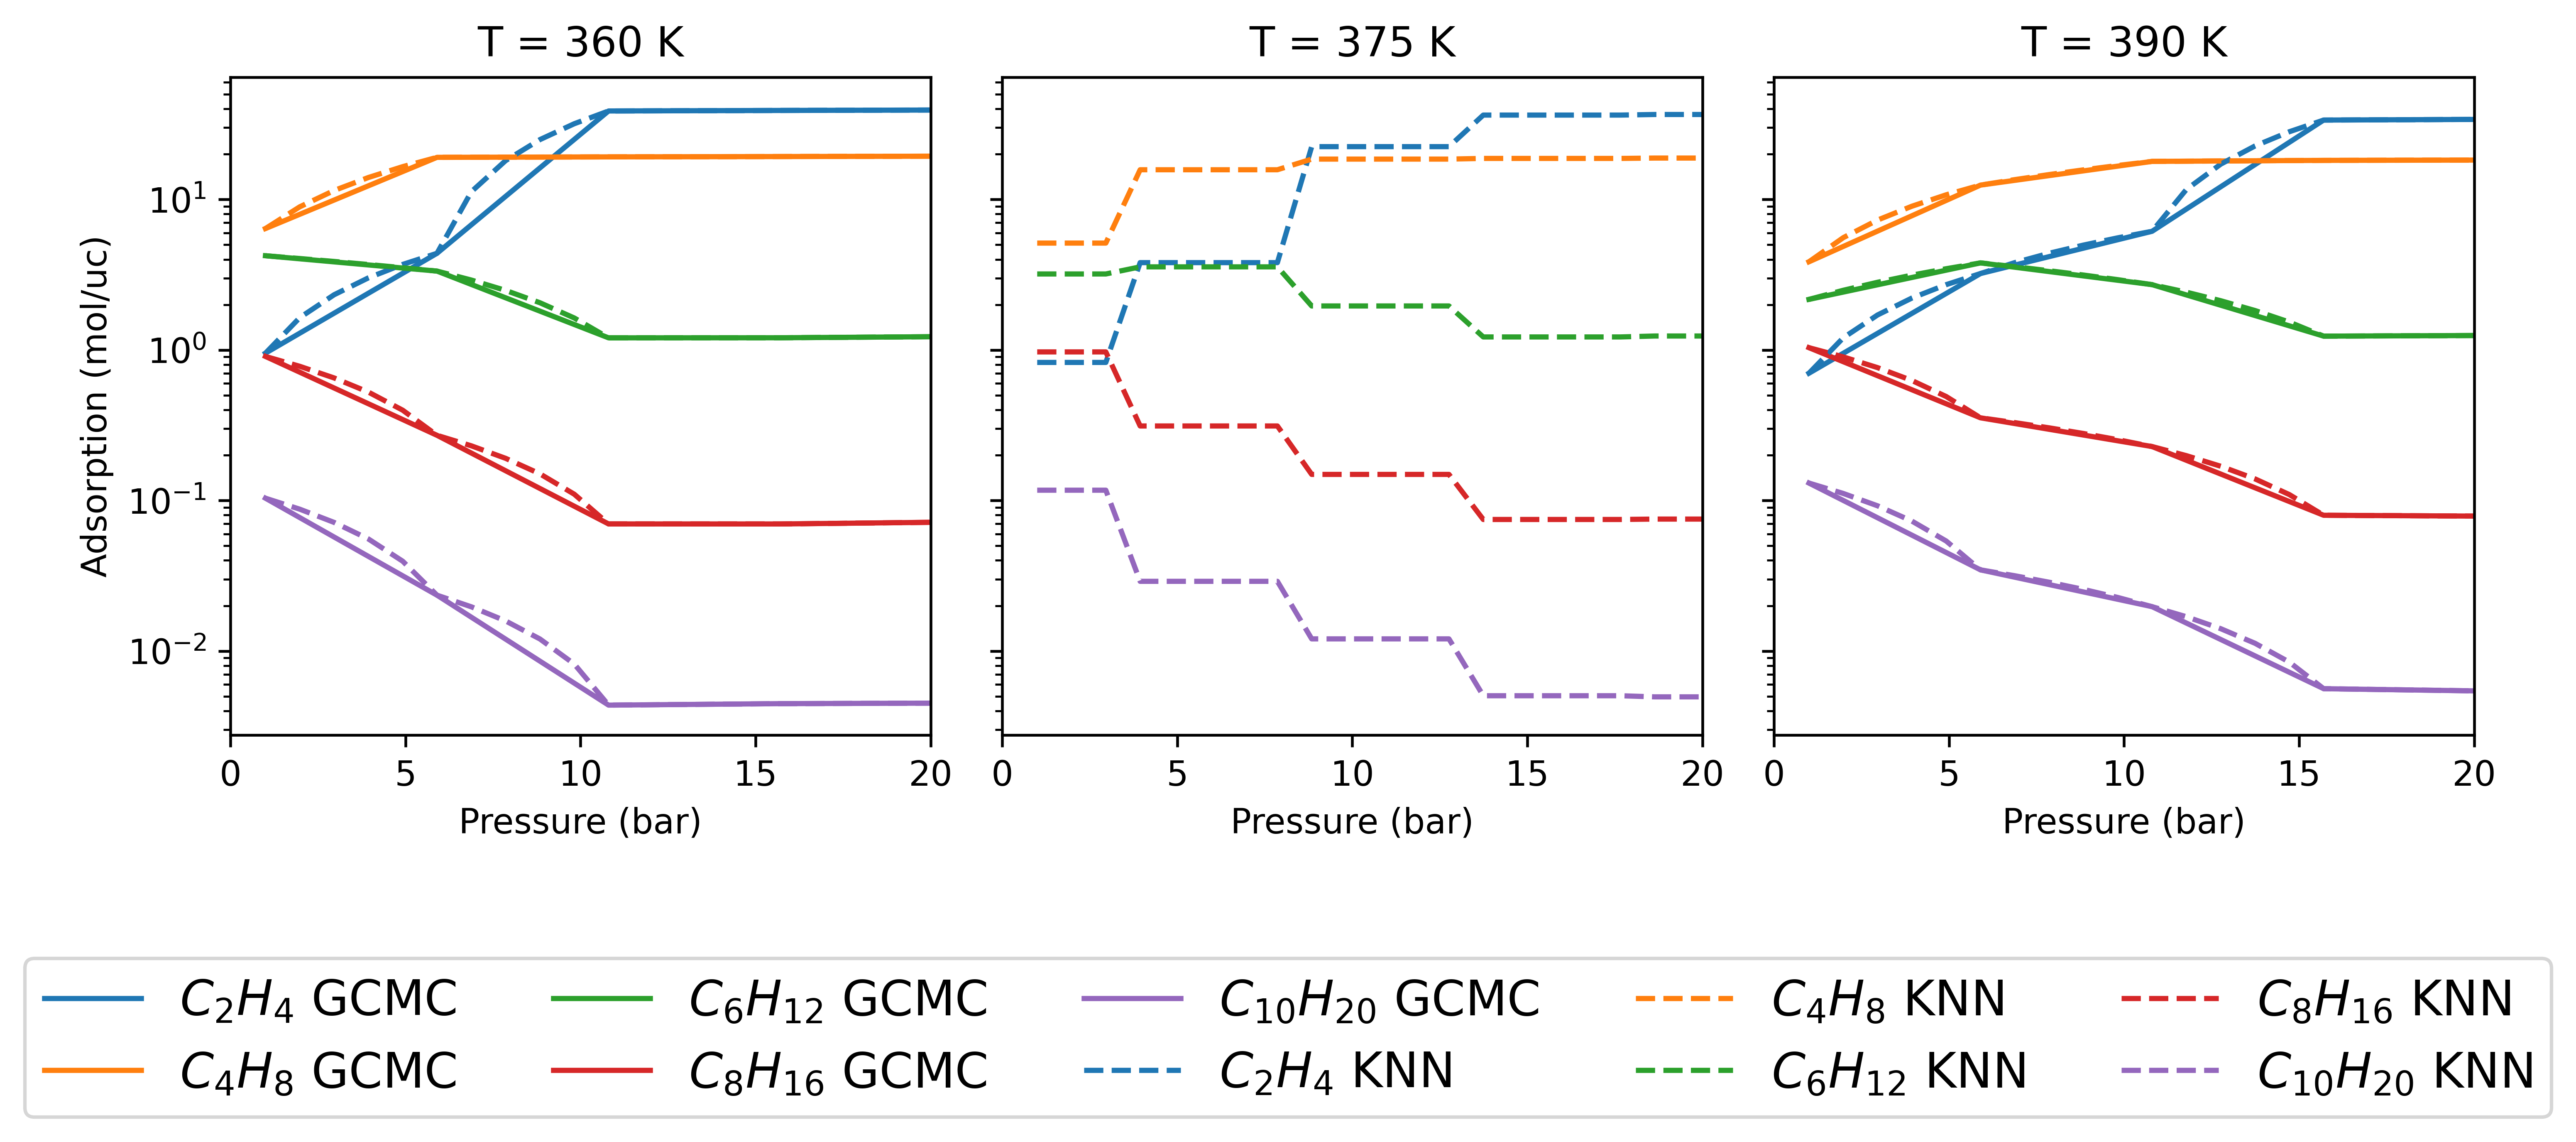

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# load your model and data
ads_model_knn = joblib.load('../data/processed/knn_adsorption_model_test.pkl')
# ads_model_gp = joblib.load('../data/adsorption/adsorption_gp_model.pkl')

# define the six temperatures: 300, 330, 360, 390, 420, 450
# temps = [300 + 30 * i for i in range(5)]
# temps.append(410)
# temps.sort()
temps = [360, 375, 390]
# keep your same color‐mapping
palette = dict(zip(
    range(2, 11, 2),
    sns.color_palette('tab10', n_colors=5)
))

# set up a 2×3 figure
fig, axes = plt.subplots(1, 3, figsize=(10, 4), dpi=600, sharex=True, sharey=True)
axes = axes.flatten()

# common pressure axis
m = 51
pressure = np.linspace(1, 50, m)

for ax, T in zip(axes, temps):
    # plot the existing data
    sns.lineplot(
        data=data.query(
            'temperature == @T and adsorption_type=="absolute"'
        ),
        x='pressure_bar', y='mol_uc_avg',
        hue='n', palette=palette,
        ax=ax
    )

    # compute and plot predictions
    for n_val in range(2, 11, 2):
        X_test = pd.DataFrame({
            'pressure_bar': pressure,
            'temperature': [T] * m,
            'n':           [n_val] * m,
            'adsorption_type_num': [0] * m
        })
        y_pred = ads_model_knn(X_test)
        ax.plot(
            pressure, y_pred,
            color=palette[n_val],
            linestyle='--',
            label=f'pred (n={n_val})'
        )

    ax.set_yscale('log')
    ax.set_title(f'T = {T} K')
    ax.set_xlabel('Pressure (bar)')
    ax.set_ylabel('Adsorption (mol_uc_avg)')
    ax.legend(fontsize='small', loc='upper left')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend_.remove()
    ax.set_xlim(0, 20)

labels = [f'$C_{{{n}}}H_{{{2*n}}}$ GCMC' for n in range(2, 11, 2)]
labels += [f'$C_{{{n}}}H_{{{2*n}}}$ KNN' for n in range(2, 11, 2)]
fig.legend(
    handles=handles, labels=labels,
    title='',
    loc='upper center', bbox_to_anchor=(0.5, 0.05),
    ncol=5, fontsize=14
)
axes[0].set_ylabel('Adsorption (mol/uc)')
fig.tight_layout()
plt.subplots_adjust(bottom=0.25)  # Make room for the legend at the bottom
fig.savefig('../experiments/files/plots/knn_adsorption_model_comparison.pdf', bbox_inches='tight', dpi=600)

## Check models

/tmp/ipykernel_8622/3071225749.py:28: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(


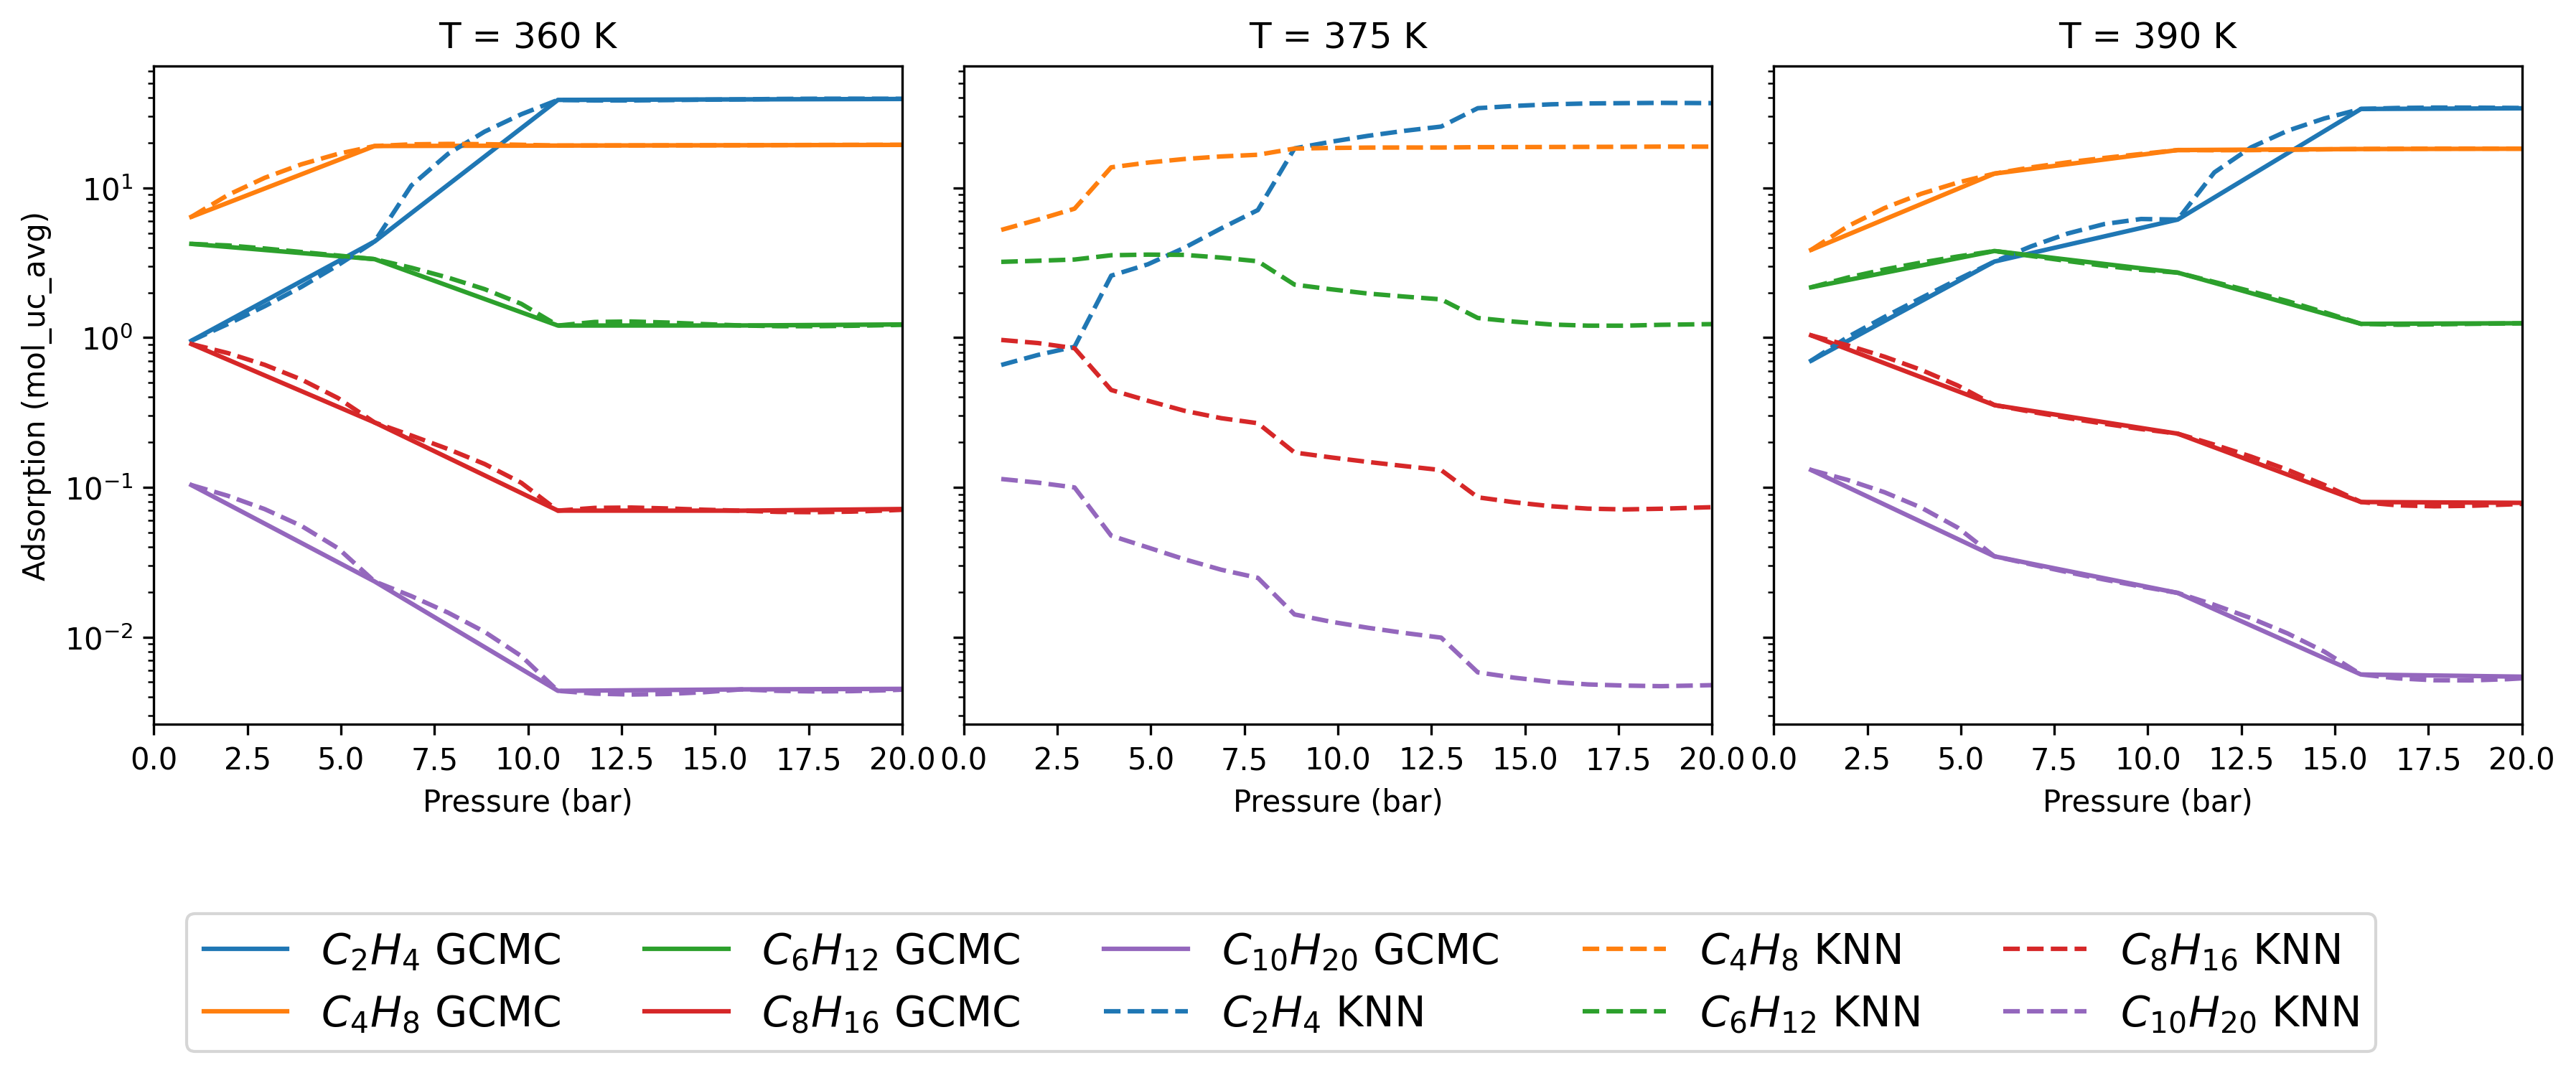

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# load your model and data
ads_model = joblib.load('../data/adsorption/adsorption_ensemble_model.pkl')

# define the six temperatures: 300, 330, 360, 390, 420, 450
# temps = [300 + 30 * i for i in range(5)]
# temps.append(410)
# temps.sort()
temps = [360, 375, 390]
# keep your same color‐mapping
palette = dict(zip(
    range(2, 11, 2),
    sns.color_palette('tab10', n_colors=5)
))

# set up a 2×3 figure
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=300, sharex=True, sharey=True)
axes = axes.flatten()

# common pressure axis
m = 51
pressure = np.linspace(1, 50, m)

for ax, T in zip(axes, temps):
    # plot the existing data
    sns.lineplot(
        data=data.query(
            'temperature == @T and adsorption_type=="absolute"'
        ),
        x='pressure_bar', y='mol_uc_avg',
        hue='n', palette=palette,
        ax=ax
    )

    # compute and plot predictions
    for n_val in range(2, 11, 2):
        X_test = pd.DataFrame({
            'pressure_bar': pressure,
            'temperature': [T] * m,
            'n':           [n_val] * m,
            'adsorption_type_num': [0] * m
        })
        y_pred = ads_model.predict(X_test)
        ax.plot(
            pressure, y_pred,
            color=palette[n_val],
            linestyle='--',
            label=f'pred (n={n_val})'
        )

    ax.set_yscale('log')
    ax.set_title(f'T = {T} K')
    ax.set_xlabel('Pressure (bar)')
    ax.set_ylabel('Adsorption (mol_uc_avg)')
    ax.legend(fontsize='small', loc='upper left')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend_.remove()
    ax.set_xlim(0, 20)

labels = [f'$C_{{{n}}}H_{{{2*n}}}$ GCMC' for n in range(2, 11, 2)]
labels += [f'$C_{{{n}}}H_{{{2*n}}}$ KNN' for n in range(2, 11, 2)]
fig.legend(
    handles=handles, labels=labels,
    title='',
    loc='upper center', bbox_to_anchor=(0.5, -0.05),
    ncol=5, fontsize=14
)
fig.tight_layout()
plt.show()

# Improve this model for prediction beyond $C_{10}H_{20}$

In [10]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
import joblib
from kinetic_model.constants.adsorption import AdsorptionKNN
# load your model and data
ads_model_loaded = joblib.load('../data/processed/knn_adsorption_model.pkl')


data = {'pressure_bar': [],
    'temperature': [],
    'n': [],
    'adsorption_type_num': []}

for n in range(2, 11, 2):
    for T in range(300, 601, 30):
        for p in range(1, 51):
            for ads_type in range(2):
                data['pressure_bar'].append(p)
                data['temperature'].append(T)
                data['n'].append(n)
                data['adsorption_type_num'].append(ads_type)

data = pd.DataFrame(data)
y_pred = ads_model_loaded(data)
data['mol_uc_avg'] = y_pred
data.head()

,pressure_bar,temperature,n,adsorption_type_num,mol_uc_avg
0,1,300,2,0,2.029520
1,1,300,2,1,1.933677
2,2,300,2,0,11.731506
3,2,300,2,1,8.014903
4,3,300,2,0,21.433491


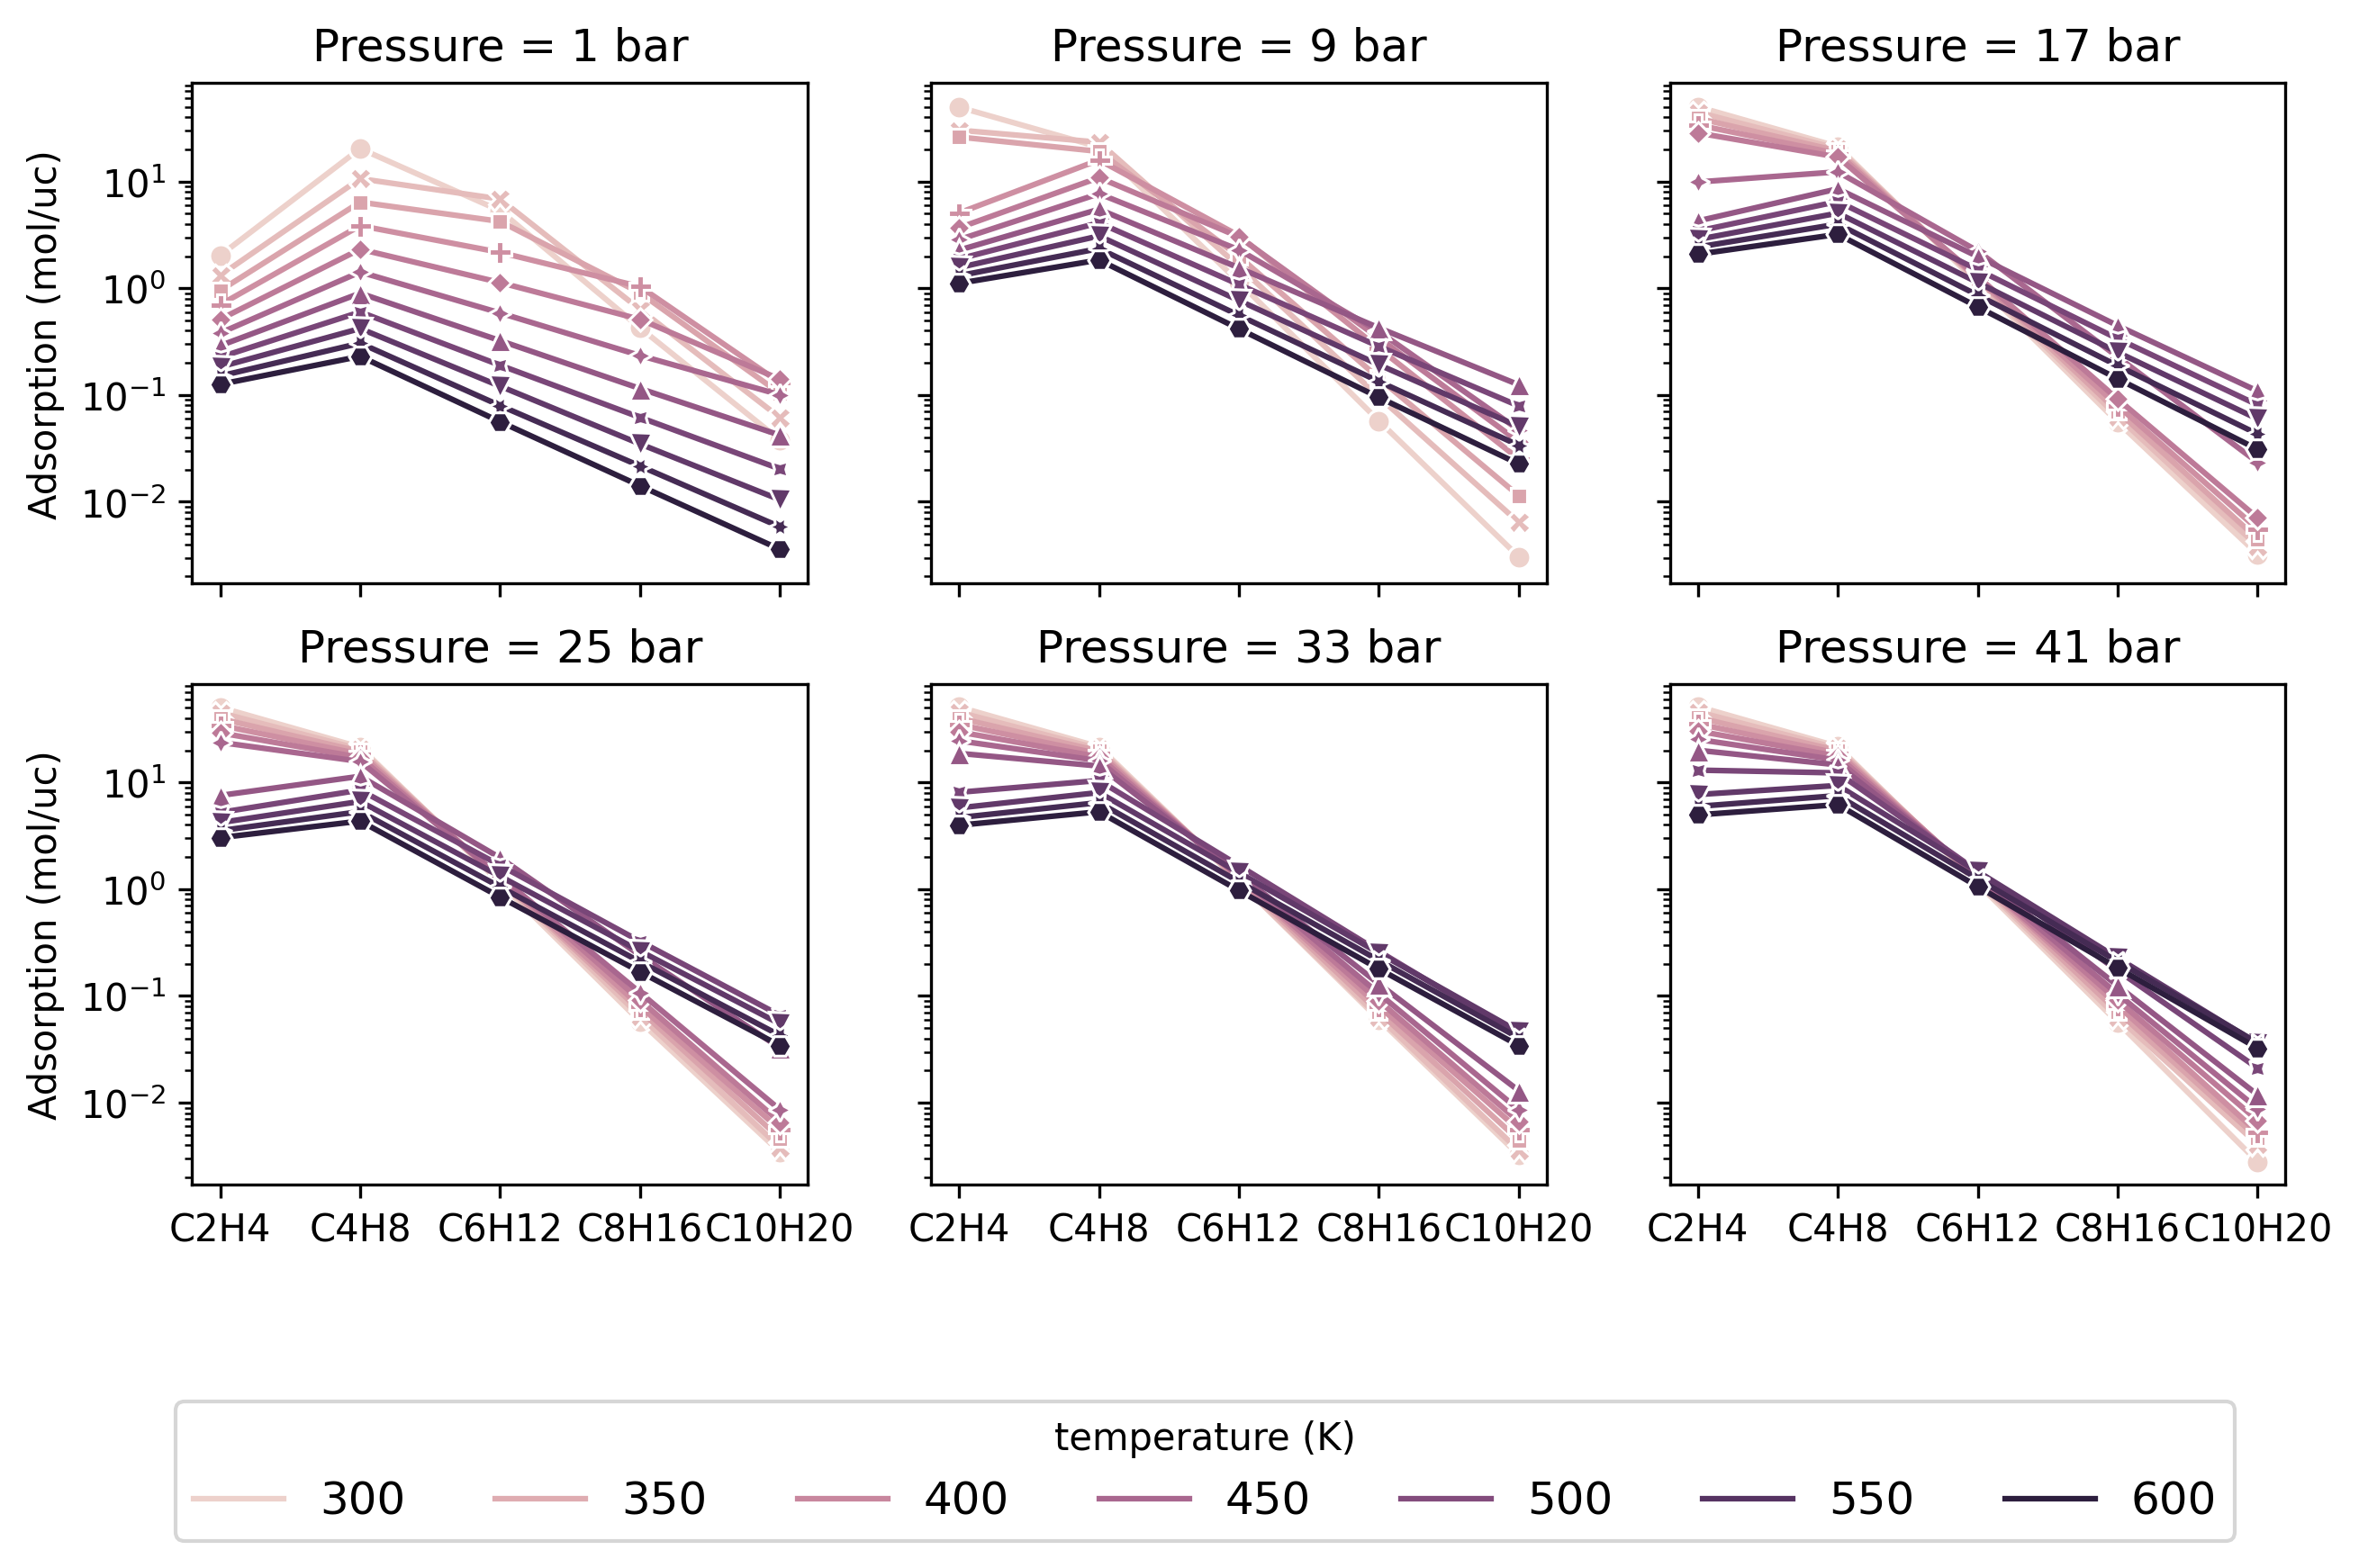

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axs = plt.subplots(2, 3, figsize=(10, 6), dpi=300, sharex=True, sharey=True)

for pressure, ax in zip(list(range(1, 51, 8)), axs.flatten()):
    sns.lineplot(data = data.query('pressure_bar == @pressure and adsorption_type_num == 0'),
                 x = 'n', y = 'mol_uc_avg', hue = 'temperature', style='temperature', markers=True, dashes=False, ax=ax)
    
    ax.set_yscale('log')
    ax.set_title(f'Pressure = {pressure} bar')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_xticks(
        ticks=range(2, 11, 2),
        labels=[f'C{n}H{2*n}' for n in range(2, 11, 2)]
    )
    ax.set_xlabel('')

axs[0,0].set_ylabel('Adsorption (mol/uc)')
axs[1,0].set_ylabel('Adsorption (mol/uc)')

fig.legend(handles=handles[:7], labels=labels[:7], loc='upper center', 
           bbox_to_anchor=[0.5, 0.08], ncol=7, fontsize=12, title='temperature (K)')

plt.subplots_adjust(bottom=0.2)  # Make room for the legend at the bottom
fig.savefig('../experiments/files/plots/knn_adsorption_slope.pdf', bbox_inches='tight', dpi=300)

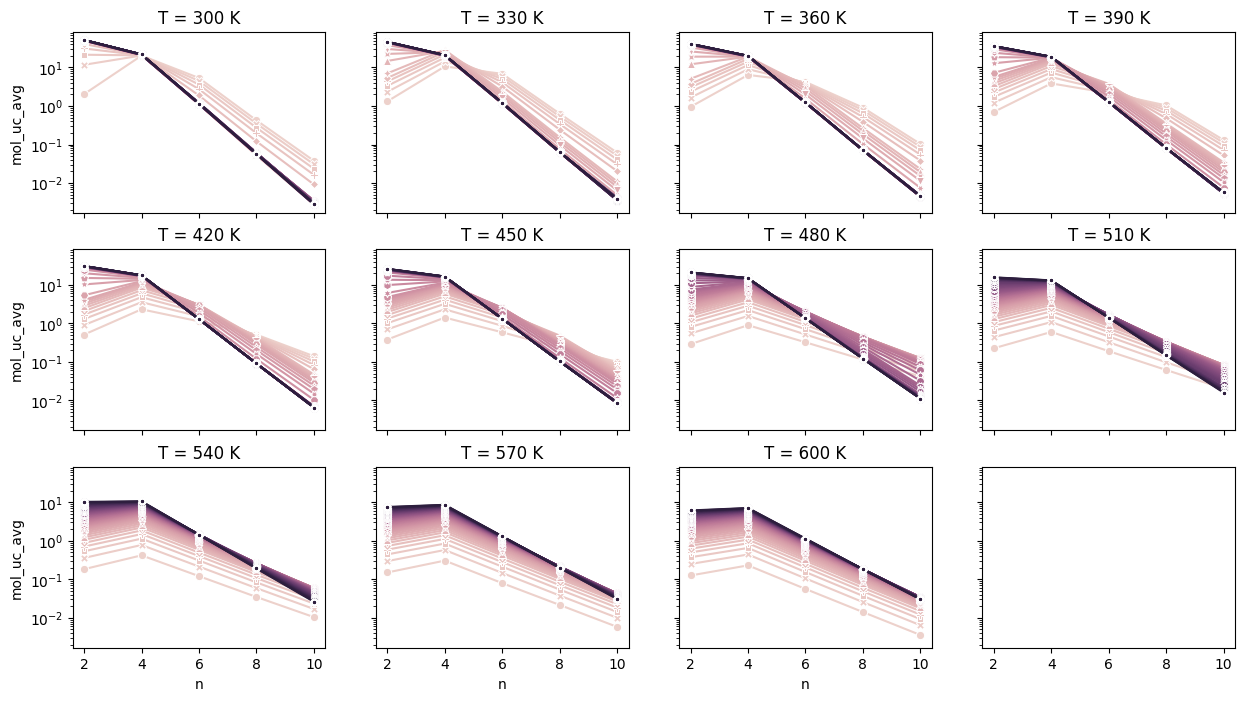

In [13]:
fig, axs = plt.subplots(3, 4, figsize=(15, 8), dpi=100, sharex=True, sharey=True)

for temperature, ax in zip(list(range(300, 601, 30)), axs.flatten()):
    sns.lineplot(data = data.query('adsorption_type_num == 0 and temperature == @temperature'),
                 x = 'n', y = 'mol_uc_avg', hue = 'pressure_bar', style='pressure_bar', 
                 markers=True, dashes=False, ax=ax)
    ax.set_yscale('log')
    ax.set_title(f'T = {temperature} K')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

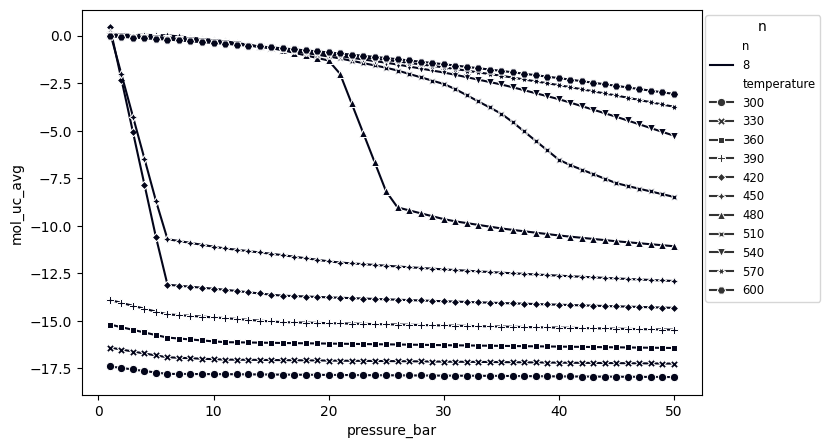

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5), dpi=100)

sns.lineplot(data=data.query('n == 8 and adsorption_type_num == 1'), 
                x='pressure_bar', y='mol_uc_avg', hue='n', 
                style='temperature', markers=True, dashes=False,
                ax=ax, palette='rocket')

ax.legend(title='n', fontsize='small', loc='upper right', bbox_to_anchor=(1.2, 1))

<Axes: xlabel='percentage_error', ylabel='Count'>

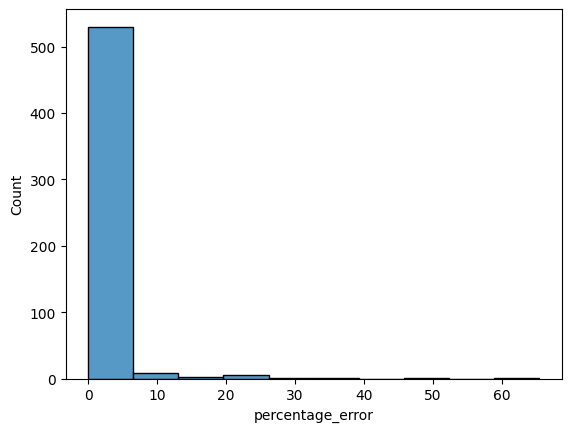

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso


def check_linearity(X_train, y_train, X_test, y_test):
    """
    Fit a linear regression model to the input data.

    Parameters
    ----------
    X : pandas.DataFrame or numpy.ndarray
        Feature matrix (shape: [n_samples, n_features])
    y : array-like
        Target values (shape: [n_samples])

    Returns
    -------
    model : sklearn.linear_model.LinearRegression
        Fitted linear regression model
    """
    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
    percentage_error = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
    return rmse, percentage_error


adsorption_type = 0

errors = []

for pressure in data.pressure_bar.unique():
    for temperature in data.temperature.unique():
        dft = data.query('pressure_bar == @pressure and temperature == @temperature and adsorption_type_num == @adsorption_type').copy()
        X_train = dft.loc[dft.n.between(6, 8), ['pressure_bar', 'temperature', 'n']]
        X_test = dft.loc[dft.n > 8, ['pressure_bar', 'temperature', 'n']]
        y_train = dft.loc[dft.n.between(6, 8), 'mol_uc_avg']
        y_train = np.log10(y_train)
        y_test = dft.loc[dft.n > 8, 'mol_uc_avg']
        y_test = np.log10(y_test)
        rmse, percentage_error = check_linearity(X_train, y_train, X_test, y_test)
        errors.append((pressure, temperature, rmse, percentage_error))

errors_df = pd.DataFrame(errors, columns=['pressure', 'temperature', 'rmse', 'percentage_error'])

sns.histplot(data=errors_df, x='percentage_error', bins=10)

In [16]:
big_errors = errors_df[errors_df.percentage_error > 10]
big_errors

,pressure,temperature,rmse,percentage_error
2,1,360,0.272867,27.707606
3,1,390,0.578628,65.439189
4,1,420,0.215477,25.291208
13,2,360,0.232357,21.933178
14,2,390,0.462256,48.413847
15,2,420,0.119750,13.087317
24,3,360,0.183697,15.980807
25,3,390,0.346157,33.312615
36,4,390,0.226675,19.816959
38,4,450,0.145638,13.019184


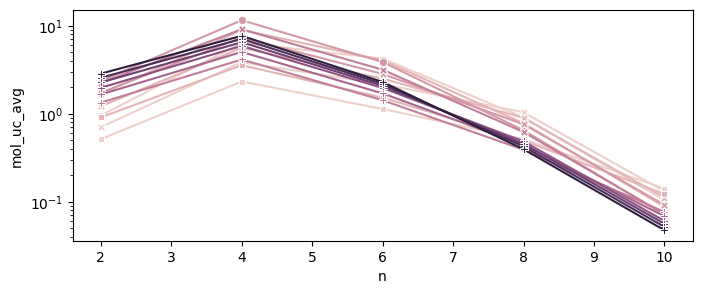

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(8, 3), dpi=100)

big_deviation = []
for pressure, temperature in zip(big_errors.pressure, big_errors.temperature):
    dft = data.query('pressure_bar == @pressure and temperature == @temperature and adsorption_type_num == @adsorption_type').copy()
    big_deviation.append(dft)
big_deviation = pd.concat(big_deviation)

sns.lineplot(data=big_deviation, x='n', y='mol_uc_avg', hue='pressure_bar', style='temperature', markers=True, dashes=False, ax=ax)
ax.set_yscale('log')
ax.legend().remove()

## Try

In [18]:
from kinetic_model.constants.adsorption import AdsorptionKNN, AdsorptionKNNSlopeExtrap

import numpy as np
import pandas as pd


ads_model = AdsorptionKNNSlopeExtrap(n_neighbors=2)
ads_model.fit(data, y_col='mol_uc_avg')
joblib.dump(ads_model, '../data/processed/knn_adsorption_slope_model.pkl')

['../data/processed/knn_adsorption_slope_model.pkl']

In [20]:
ads_model = joblib.load('../data/adsorption/adsorption_gp_model.pkl')
pressure = 20
temperature = 330
ads_type_num = 1
dft = data.query('pressure_bar == @pressure and temperature == @temperature and adsorption_type_num == @ads_type_num').copy()

dft = pd.concat([
    dft,
    pd.DataFrame({
        'pressure_bar': [pressure] * 5,
        'temperature': [temperature] * 5,
        'n': range(12, 21, 2),
        'adsorption_type_num': [ads_type_num] * 5
    })
])

predicted = ads_model(dft)
dft['predicted'] = predicted
dft

,pressure_bar,temperature,n,adsorption_type_num,mol_uc_avg,predicted
139,20,330,2,1,27.564986,27.634424
1239,20,330,4,1,3.210585,3.207566
2339,20,330,6,1,-15.977856,-15.988902
3439,20,330,8,1,-17.083991,-17.088885
4539,20,330,10,1,-17.142491,-17.146179
0,20,330,12,1,NaN,-17.146179
1,20,330,14,1,NaN,-17.146179
2,20,330,16,1,NaN,-17.146179
3,20,330,18,1,NaN,-17.146179
4,20,330,20,1,NaN,-17.146179


In [21]:
ads_model = joblib.load('../data/processed/knn_adsorption_slope_model.pkl')
ads_model = joblib.load('../data/adsorption/adsorption_gp_model.pkl')
data_extended = pd.concat([
    data,
    data.assign(n=data['n'] + 10)])

data_extended['mol_uc_avg'] = ads_model(data_extended)

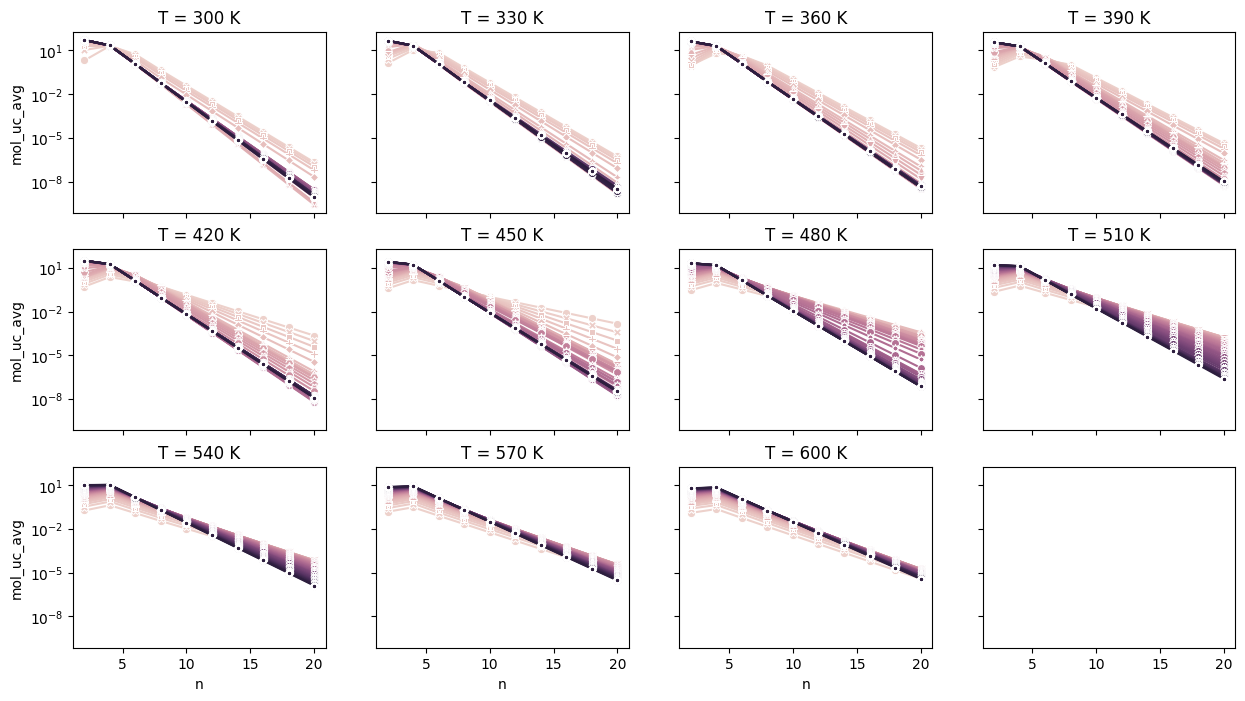

In [22]:
fig, axs = plt.subplots(3, 4, figsize=(15, 8), dpi=100, sharex=True, sharey=True)

for temperature, ax in zip(list(range(300, 601, 30)), axs.flatten()):
    sns.lineplot(data = data_extended.query('adsorption_type_num == 0 and temperature == @temperature'),
                 x = 'n', y = 'mol_uc_avg', hue = 'pressure_bar', style='pressure_bar', 
                 markers=True, dashes=False, ax=ax)
    ax.set_yscale('log')
    ax.set_title(f'T = {temperature} K')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

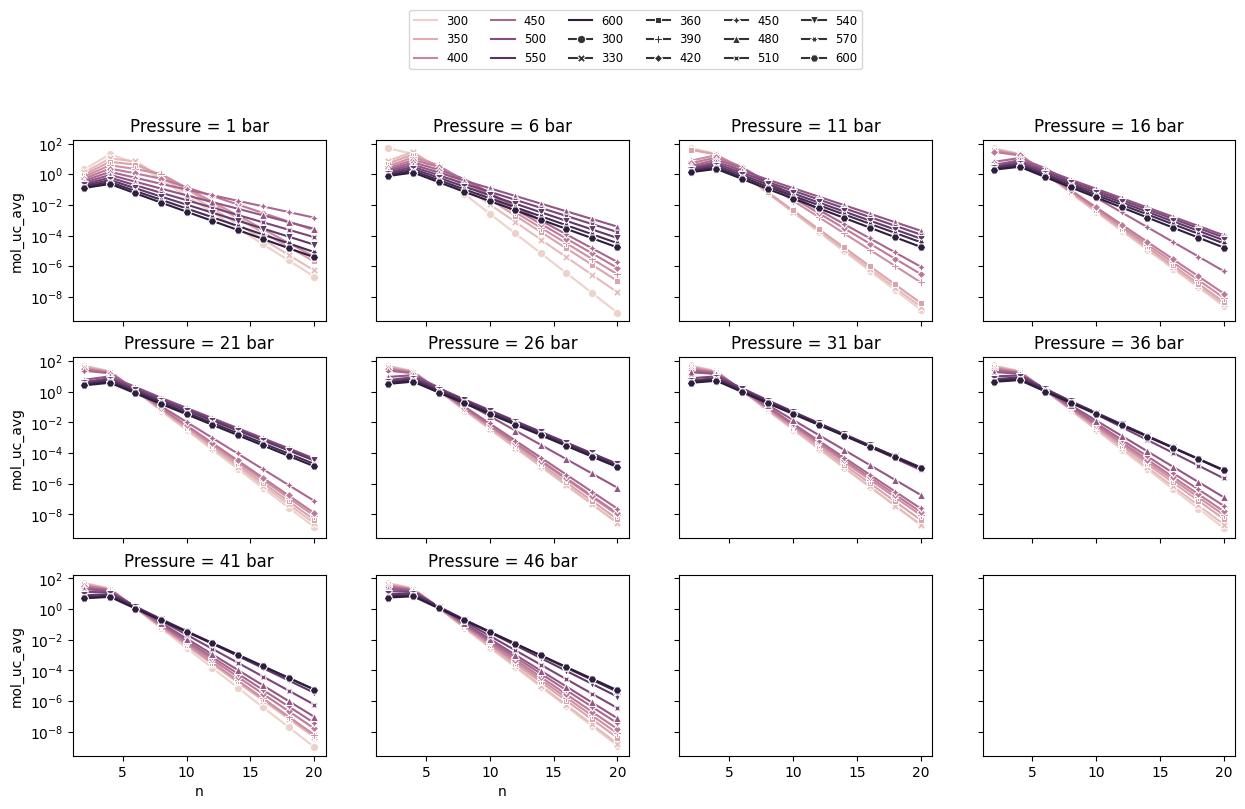

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
fig, axs = plt.subplots(3, 4, figsize=(15, 8), dpi=100, sharex=True, sharey=True)

for pressure, ax in zip(list(range(1, 51, 5)), axs.flatten()):
    sns.lineplot(data = data_extended.query('pressure_bar == @pressure and adsorption_type_num == 0'),
                 x = 'n', y = 'mol_uc_avg', hue = 'temperature', style='temperature', markers=True, dashes=False, ax=ax)
    
    ax.set_yscale('log')
    ax.set_title(f'Pressure = {pressure} bar')
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

fig.legend(handles=handles, labels=labels, loc='upper center', 
           bbox_to_anchor=[0.5, 1.05], ncol=6, fontsize='small')

In [25]:
ads_model = joblib.load('../data/processed/knn_adsorption_slope_model.pkl')
ads_model = joblib.load('../data/adsorption/adsorption_gp_model.pkl')
dft = data.copy()
dft['temperature'] += 15
dft = dft[dft.temperature < 600]
predicted = ads_model(dft)
dft['mol_uc_avg'] = predicted
dft.head()

,pressure_bar,temperature,n,adsorption_type_num,mol_uc_avg
0,1,315,2,0,2.973861
1,1,315,2,1,2.456011
2,2,315,2,0,6.746457
3,2,315,2,1,4.940729
4,3,315,2,0,11.613443


<Axes: xlabel='pressure_bar', ylabel='mol_uc_avg'>

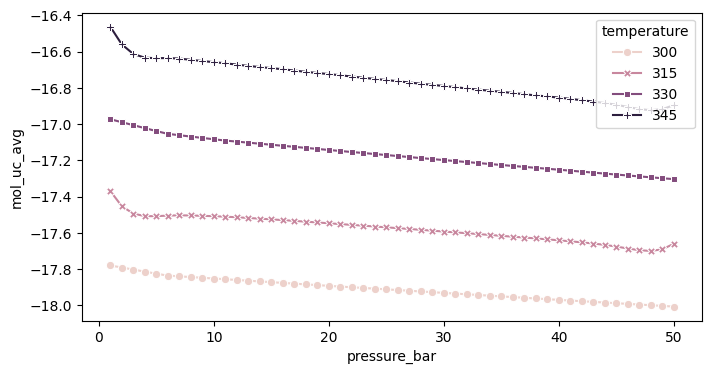

In [26]:
fig, axs = plt.subplots(1, 1, figsize=(8, 4), dpi=100, sharex=True, sharey=True)
n = 10
comparision = pd.concat([
    dft.query('adsorption_type_num == 1 & n == @n and temperature < 350'),
    data.query('adsorption_type_num == 1 & n == @n and temperature < 350')
])

sns.lineplot(data = comparision, x='pressure_bar', y='mol_uc_avg', 
             hue='temperature', style='temperature', markers=True, dashes=False, ax=axs)

# axs.set_yscale('log')

# Estimate error